In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('../')


from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch

from utils.custom_loader import custom_loader_training
from utils.mm_classifier import mm_classifier
from utils.custom_a_handles import custom_normalize, custom_to_tensor, custom_gauss_noise, custom_normalize99

#using albumentations library
import albumentations as A
#import albumentations.augmentations.functional as F
from albumentations.pytorch import ToTensorV2

# from utils.unet import UNet
from utils.unet import UNet, UNet_deep

from skimage import io
import cv2
import matplotlib.pyplot as plt
import numpy as np

from utils.load_files import getTrainingPairs

from sklearn.model_selection import train_test_split
import time, datetime

from utils.cell_aware_crop import CellAwareCrop

from main import train_net
from imageio.v3 import imwrite


In [ ]:
# Set training parameters for trap detection
train_dirs =[
                #('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data_traps_cropped', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/chip_masks', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/chip_masks', ''),
                ]
save_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769'
net_size = 512
crop_window = 512
normalize = custom_normalize99
num_epochs = 120

#use albumentations library
training_transform = A.Compose(
    [   
        #A.RandomRotate90(p=1),
        A.RandomCrop(crop_window, crop_window, p=1),
        #CellAwareCrop(p=1,crop_size=crop_window, min_cell_fraction=0.05, max_attempts=20),
        #A.GridDistortion(p=0.4),
        #A.ElasticTransform(p=0.4, alpha=50, sigma=20),
        A.Affine(p=0.8, translate_percent=(-0.2, 0.2), scale=(0.75, 1.25), rotate=(-5, 5)),
        A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 2.0)),
        #A.GaussNoise(std_range=(2/255, 20/255), mean_range=(0, 0), p=0.5),
        #A.Lambda(name='gauss-noise', image=custom_gauss_noise, p=0.5),
        #A.GridDropout(p=0.3, ratio=0.3, random_offset=True),
        A.Lambda(name='normalize', image=normalize, p=1.0),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0)
    ]
    )

In [3]:
# Set training parameters for cell segmentation
train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train', '')
                ]
save_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769'
net_size = 512
crop_window = 512
normalize = custom_normalize99
num_epochs = 120

#use albumentations library
training_transform = A.Compose(
    [   
        #A.RandomRotate90(p=1),
        A.HorizontalFlip(p=0.5),
        A.RandomCrop(crop_window, crop_window, p=1),
        #CellAwareCrop(p=1,crop_size=crop_window, min_cell_fraction=0.05, max_attempts=20),
        #A.GridDistortion(p=0.4),
        #A.ElasticTransform(p=0.4, alpha=50, sigma=20),
        A.Affine(p=0.8, translate_percent=(-0.2, 0.2), scale=(0.75, 1.25), rotate=(-5, 5)),
        A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 2.0)),
        #A.GaussNoise(std_range=(2/255, 20/255), mean_range=(0, 0), p=0.5),
        A.Lambda(name='gauss-noise', image=custom_gauss_noise, p=0.5),
        #A.GridDropout(p=0.3, ratio=0.3, random_offset=True),
        A.Lambda(name='normalize', image=normalize, p=1.0),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0)
    ]
    )

Number of phase images: 563
Number of binary masks : 563
training epoch 1
loss: 1.0505454764298514
training epoch 2
loss: 0.9917577268384027
training epoch 3
loss: 0.9458887746148076
training epoch 4
loss: 0.9261418162508214
training epoch 5
loss: 0.9066604016520453
training epoch 6
loss: 0.8762614101382857
training epoch 7
loss: 0.8689648115888555
training epoch 8
loss: 0.8550828109818993
training epoch 9
loss: 0.8560426036516825
training epoch 10
loss: 0.8350753323406193
training epoch 11
loss: 0.8235346617850852
training epoch 12
loss: 0.8424198033539116
training epoch 13
loss: 0.8182902570734633
training epoch 14
loss: 0.8236182928085327
training epoch 15
loss: 0.8126103400338626
training epoch 16
loss: 0.8182454419896957
training epoch 17
loss: 0.8081776186929527
training epoch 18
loss: 0.8033250454047047
training epoch 19
loss: 0.7932899719011699
training epoch 20
loss: 0.79335259630325
training epoch 21
loss: 0.7900541262001011
training epoch 22
loss: 0.7782725438158563
training

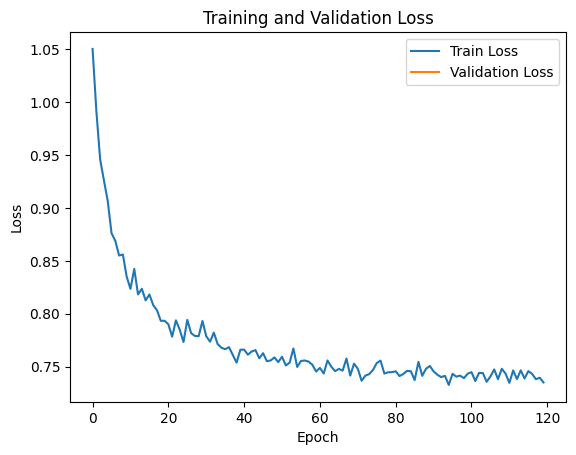

In [4]:
# Run training
train_net(train_dirs,save_dir, net_size=512, training_transform=training_transform, num_epochs=num_epochs, normalize=normalize)

In [6]:
from skimage.transform import resize, rescale

def pad_image(img, pad=16):
    x,y = np.shape(img)
    xpad, ypad = 0, 0
    if x%pad != 0:
        xpad = pad-(x%pad)
    if y%pad != 0:
        ypad = pad-(y%pad)    
    padded_img = np.pad(img, ((0,xpad),(0,ypad)),'constant',constant_values=(0,0))
    return padded_img, x, y

def resize_image(img,scale=0.5):
    return rescale(img,scale,mode='constant',clip=True,preserve_range=True,anti_aliasing=True).astype(img.dtype)

def resize_mask(img,shape):
    return resize(img,shape,order=0,mode='constant',preserve_range=True,anti_aliasing=False).astype(img.dtype)

def custom_normalize99(image, lower=0.01, upper=99.99):
    #print(image.dtype)
    image = np.array(image).astype(np.float32)
    image_copy = image.copy()
    return np.interp(image_copy, 
                     (np.percentile(image_copy, lower), np.percentile(image_copy, upper)), (0, 1)).astype(np.float32)

def custom_normalize(image):
    img = img.astype('float32')
    mean = np.mean(image)
    std = np.std(image)
    if std < 1e-6:                          # guard against flat/empty patches
        return np.zeros_like(image, dtype=np.float32)
    return ((image - mean) / std).astype(np.float32)

def segment_unet(img, model, threshold=0.5, min_size=100, normalize=custom_normalize):
    
    img, xorg, yorg = pad_image(img)
    
    img = normalize(img).astype('float32')
    #img = (img - np.mean(img)) / np.std(img)
    img = torch.from_numpy(img).unsqueeze(0).unsqueeze(0).cuda()
    res = model(img)
    res = torch.sigmoid(res)
    res = res.to("cpu").detach().numpy().squeeze(0).squeeze(0)
    
    res = res[0:xorg,0:yorg]
    mask = res > threshold
    #mask = remove_small_objects(mask,max_size=min_size)

    mask = mask.astype('uint8')
    return mask

In [ ]:
# Validate masks
trap_net = UNet(max_filters = 512)
NET_PATH = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_512_260715_204425.pth'
#NET_PATH = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_512_260708_172848.pth'
saved_net = torch.load(NET_PATH)
trap_net.load_state_dict(saved_net['model_state_dict']);
trap_net.eval();
trap_net.cuda();

#images,_ = getTrainingPairs([train_dirs[1]])
#res_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/cell_masks_512_260715_204425'
images,_ = getTrainingPairs([train_dirs[3]])
res_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/cell_masks_512_260708_172848'
import os
os.makedirs(res_dir,exist_ok=True)
with torch.no_grad():
    for fi, f in enumerate(images):
        im = io.imread(f)
        filename = f.split('/')[-1]
        mask = segment_unet(im,model=trap_net,threshold=0.5,normalize=normalize)
        fname = res_dir+'/'+filename
        imwrite(fname,mask, compression='zlib', compressionargs={'level':6})

In [ ]:
import functools

phase,mask=getTrainingPairs(train_dirs)
training_transform = A.Compose(
    [   
        #A.RandomRotate90(p=1),
        A.RandomCrop(crop_window, crop_window, p=1),
        #CellAwareCrop(p=1,crop_size=crop_window, min_cell_fraction=0.05, max_attempts=20),
        #A.GridDistortion(p=0.4),
        #A.ElasticTransform(p=0.4, alpha=50, sigma=20),
        #A.Affine(p=0.8, translate_percent=(-0.2, 0.2), scale=(0.75, 1.25), rotate=(-5, 5)),
        #A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 2.0)),
        #A.GaussNoise(std_range=(2/255, 20/255), mean_range=(0, 0), p=1)#0.5),
        A.Lambda(name='gauss-noise', image=functools.partial(custom_gauss_noise,sigma_range=(2,5)), p=1),
        #A.GridDropout(p=0.3, ratio=0.3, random_offset=True),
        A.Lambda(name='normalize', image=custom_normalize99, p=1.0),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0)
    ]
    )
training_dataset = custom_loader_training(phase_ims = phase,
                                          mask_ims  = mask,
                                          transform = training_transform)




(2, 5)
image range: [22.0, 255.0], noise range: [-18.310809801595912, 18.187441574877408]
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])


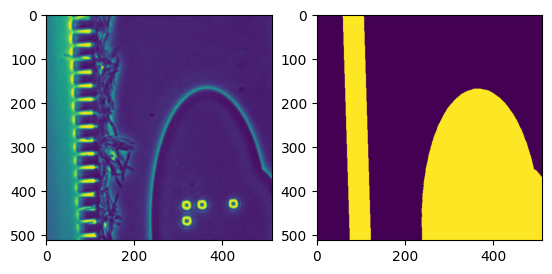

In [44]:
im, m = training_dataset[0]
print(im.shape)
print(m.shape)
fig,axs = plt.subplots(1,2)
#print(im.min())
#print(im.max())
axs[0].imshow(im.squeeze())
axs[1].imshow(m.squeeze())